In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("nassau_candy.csv")

print("Shape:", df.shape)
print(df.dtypes)

Shape: (10194, 18)
Row ID              int64
Order ID              str
Order Date            str
Ship Date             str
Ship Mode             str
Customer ID         int64
Country/Region        str
City                  str
State/Province        str
Postal Code           str
Division              str
Region                str
Product ID            str
Product Name          str
Sales             float64
Units               int64
Gross Profit      float64
Cost              float64
dtype: object


In [3]:
# Business KPI summary
kpi_summary=pd.DataFrame({
    "Metric":[
        "Total Records",
        "Unique Orders",
        "Unique Customers",
        "Unique Products",
        "Total Sales",
        "Total Units",
        "Total Gross Profit",
        "Total Cost"
    ],
    "Values":[
        len(df),
        df["Order ID"].nunique(),
        df["Customer ID"].nunique(),
        df["Product ID"].nunique(),
        df["Sales"].sum(),
        df["Units"].sum(),
        df["Gross Profit"].sum(),
        df["Cost"].sum()
    ]
})
print(kpi_summary.to_string(index=False))

            Metric    Values
     Total Records  10194.00
     Unique Orders   8549.00
  Unique Customers   5044.00
   Unique Products     15.00
       Total Sales 141783.63
       Total Units  38654.00
Total Gross Profit  93442.80
        Total Cost  48340.83


In [11]:
# Ship mode analysis
ship_mode_summary=(
    df.groupby("Ship Mode",dropna=False)
    .agg(
        Records=("Row ID","count"),
        Orders=("Order ID","nunique"),
        Sales=("Sales","sum"),
        Units=("Units","sum"),
        Gross_Profit=("Gross Profit","sum"),
        cost=("Cost","sum")
        
    )
    
).sort_values("Sales",ascending=False)
ship_mode_summary["Gross_Profit_Margin_Pct"]=(
       ship_mode_summary["Gross_Profit"]/ship_mode_summary["Sales"]*100
)
print(ship_mode_summary.round(2))

                Records  Orders     Sales  Units  Gross_Profit      cost  \
Ship Mode                                                                  
Standard Class     6120    5142  85490.35  23409      56424.46  29065.89   
Second Class       1979    1653  27860.22   7546      18306.52   9553.70   
First Class        1548    1312  21319.39   5724      14011.09   7308.30   
Same Day            547     442   7113.67   1975       4700.73   2412.94   

                Gross_Profit_Margin_Pct  
Ship Mode                                
Standard Class                    66.00  
Second Class                      65.71  
First Class                       65.72  
Same Day                          66.08  


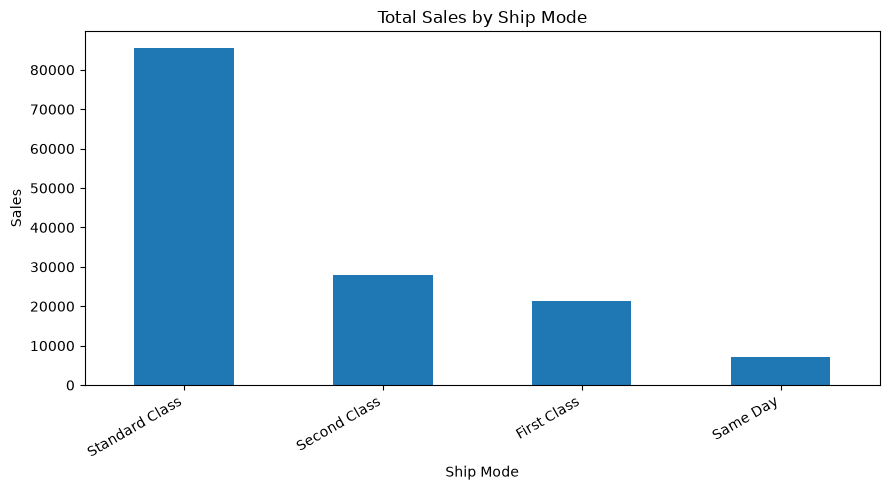

In [13]:
ship_mode_summary["Sales"].plot(kind="bar",figsize=(9,5),
                                title="Total Sales by Ship Mode",
                                ylabel="Sales")
plt.xticks(rotation=30,ha="right")
plt.tight_layout()
plt.show()

In [14]:
# Regional Analysis
region_summary=(
    df.groupby("Region")
    .agg(
        Records=("Row ID","count"),
        Orders=("Order ID","nunique"),
        Sales=("Sales","sum"),
        Units=("Units","sum"),
        Gross_Profit=("Gross Profit","sum"),
        Cost=("Cost","sum")
    )
    .sort_values("Sales",ascending=False)
) 
region_summary["Sales_Share_Pct"]=(
    region_summary["Sales"]/df["Sales"].sum()*100
)
print(region_summary.round(2))

          Records  Orders     Sales  Units  Gross_Profit      Cost  \
Region                                                               
Pacific      3253    2744  46301.53  12466      30485.94  15815.59   
Atlantic     2986    2476  41197.24  11159      26973.70  14223.54   
Interior     2335    1979  32037.60   8820      21282.49  10755.11   
Gulf         1620    1350  22247.26   6209      14700.67   7546.59   

          Sales_Share_Pct  
Region                     
Pacific             32.66  
Atlantic            29.06  
Interior            22.60  
Gulf                15.69  


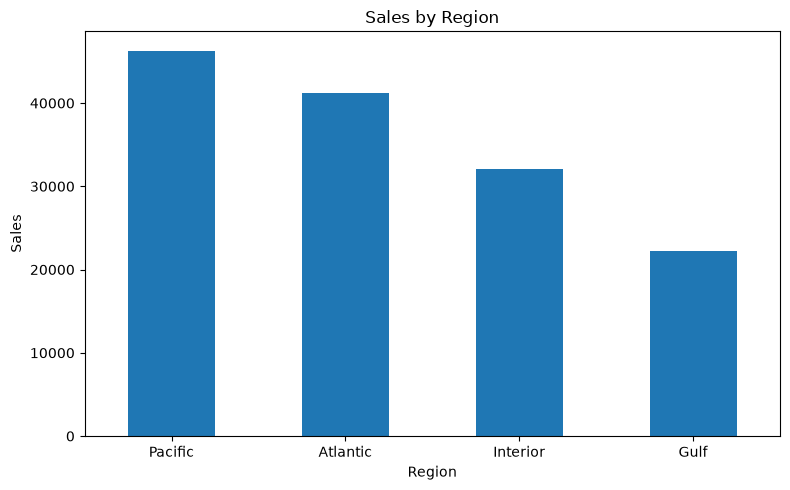

In [15]:
region_summary["Sales"].plot(
    kind="bar",
    figsize=(8,5),
    title="Sales by Region",
    ylabel="Sales"
)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [16]:
# Division Analysis
division_summary=(
    df.groupby("Division")
    .agg(
        Records=("Row ID","count"),
        Orders=("Order ID","nunique"),
        Sales=("Sales","sum"),
        Units=("Units","sum"),
        Gross_Profit=("Gross Profit","sum"),
        Cost=("Cost","sum")
    )
    .sort_values("Sales",ascending=False)
)
division_summary["Sales_Share_Pct"]=(
    division_summary["Sales"]/df["Sales"].sum()*100
)

print(division_summary.round(2))

           Records  Orders      Sales  Units  Gross_Profit      Cost  \
Division                                                               
Chocolate     9844    8205  131692.90  37275      88824.62  42868.28   
Other          310     304    9663.25   1242       4333.45   5329.80   
Sugar           40      40     427.48    137        284.73    142.75   

           Sales_Share_Pct  
Division                    
Chocolate            92.88  
Other                 6.82  
Sugar                 0.30  


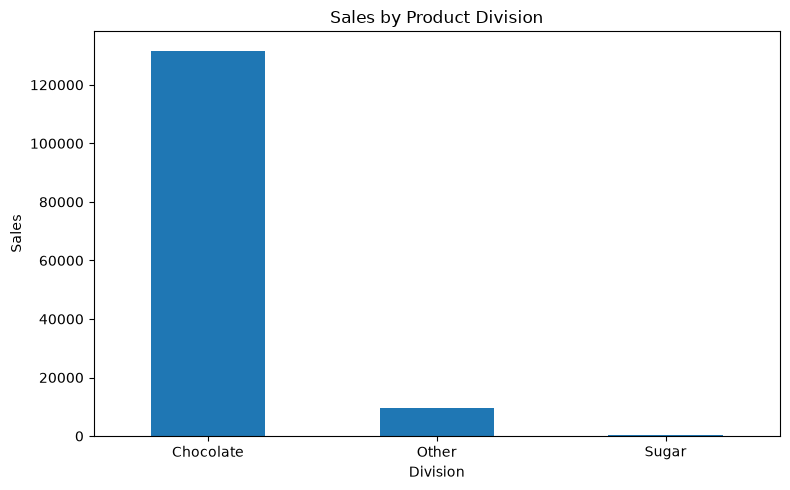

In [17]:
division_summary["Sales"].plot(
    kind="bar",
    figsize=(8,5),
    title="Sales by Product Division",
    ylabel="Sales"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [18]:
# Top 10 Sales
state_summary=(
    df.groupby("State/Province")
    .agg(
        Records=("Row ID","count"),
        Orders=("Order ID","nunique"),
        Sales=("Sales","sum"),
        Gross_Profit=("Gross Profit","sum")
    )
    .sort_values("Sales",ascending=False)
)
top_10_states=state_summary.head(10)
print(top_10_states.round(2))

                Records  Orders     Sales  Gross_Profit
State/Province                                         
California         2001    1686  27917.40      18479.42
New York           1128     942  15541.03      10222.44
Texas               985     833  13416.09       8909.53
Pennsylvania        587     487   8027.03       5225.47
Washington          506     432   6921.15       4566.64
Illinois            492     433   6898.96       4557.68
Ohio                469     392   6768.95       4413.03
Florida             383     319   4804.02       3207.11
Arizona             224     190   3587.55       2290.11
North Carolina      249     216   3450.86       2331.16


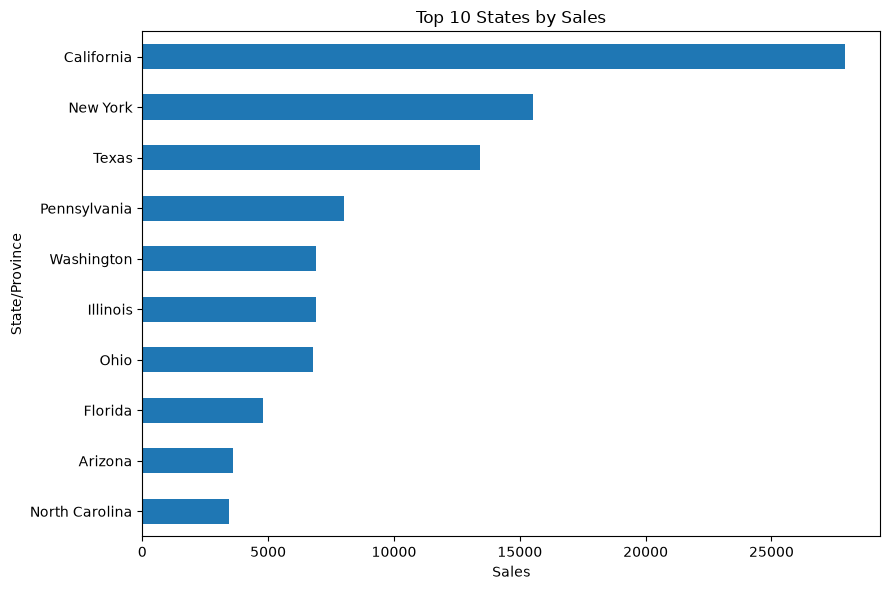

In [19]:
top_10_states["Sales"].sort_values().plot(
    kind="barh",
    figsize=(9,6),
    title="Top 10 States by Sales",
    xlabel="Sales"

)

plt.tight_layout()
plt.show()

In [20]:
# Numerical distributions and outliers
numeric_cols=["Sales","Units","Gross Profit","Cost"]
print(df[numeric_cols].describe().T)

                count       mean        std   min  25%    50%    75%    max
Sales         10194.0  13.908537  11.341020  1.25  7.2  10.80  18.00  260.0
Units         10194.0   3.791838   2.228317  1.00  2.0   3.00   5.00   14.0
Gross Profit  10194.0   9.166451   6.643740  0.25  4.9   7.47  12.25  130.0
Cost          10194.0   4.742087   5.061647  0.60  2.4   3.60   5.70  130.0


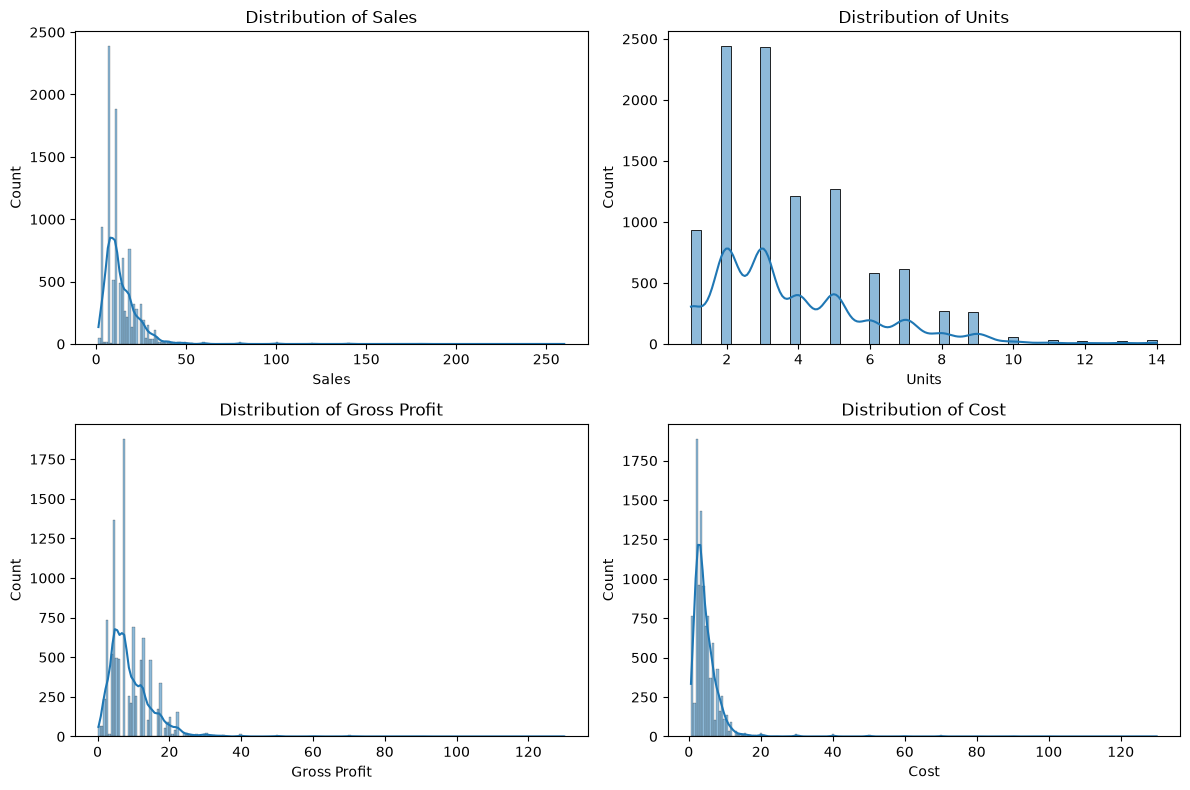

In [23]:
fig,axes=plt.subplots(2,2,figsize=(12,8))
for ax,col in zip(axes.flat,numeric_cols):
    sns.histplot(data=df,x=col,kde=True,ax=ax)
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()    